In [1]:
from sklearn.datasets import load_iris
iris = load_iris()

In [ ]:
import numpy as np
# from sklearn import datasets

def sigmod(z):
    h = 1./(1+np.exp(-z))
    return h
    
def de_sigmoid(z,h):
    return h*(1-h)
    
    
def relu(z):
    h = np.maximum(z, 0)
    return h
    
def de_relu(z,h):
    z[z <= 0] = 0
    z[z > 0] = 1.0
    return z
    
    
def no_active(z):
    h = z
    return h

def de_no_active(z,h):
    return np.ones(h.shape)
    
# o Nxc
# lab Nxc    
def loss_L2(o,lab):
    diff = lab-o
    sqrDiff = diff ** 2
    return 0.5*np.sum(sqrDiff)
    
def de_loss_L2(o,lab):
    return o-lab


def loss_CE(o,lab):    
    p = np.exp(o)/np.sum(np.exp(o),axis=1,keepdims=True)
    loss_ce = np.sum(-lab*np.log(p))
    return loss_ce

def de_loss_CE(o,lab):
    p = np.exp(o)/np.sum(np.exp(o),axis=1,keepdims=True)
    return p-lab

# dim_in:输入特征的维度
# list_num_hidden： 每层输出节点的数目
# list_act_funs： 每层的激活函数
# list_de_act_funs: 反向传播时的函数

def bulid_net(dim_in,list_num_hidden,
              list_act_funs,list_de_act_funs):
    layers=[]
    
    # 逐层的进行网络构建
    for i in range(len(list_num_hidden)):
        layer = {}
        
        # 定义每一层的权重
        if i ==0:
            # layer["w"]= 0.2*np.random.randn(dim_in,list_num_hidden[i])-0.1 # 用sigmoid激活函数
            layer["w"]= 0.01*np.random.randn(dim_in,list_num_hidden[i])  # 用relu 激活函数
        else:
            # layer["w"]= 0.2*np.random.randn(list_num_hidden[i-1],list_num_hidden[i])-0.1 # 用sigmoid激活函数
            layer["w"]= 0.01*np.random.randn(list_num_hidden[i-1],list_num_hidden[i]) # 用relu 激活函数
        
        # 定义每一层的偏置
        layer["b"] = 0.1*np.ones([1,list_num_hidden[i]])
        layer["act_fun"]= list_act_funs[i]
        layer["de_act_fun"]= list_de_act_funs[i]
        layers.append(layer)
        
    return layers
    
    
# 返回每一层的输入
# 与最后一层的输出
def fead_forward(datas,layers):
    input_layers = []
    input_acfun = []
    for i in range(len(layers)):
        layer = layers[i]
        if i ==0:
            inputs = datas
            z = np.dot(inputs,layer["w"]) + layer["b"]
            h = layer['act_fun'](z)
            input_layers.append(inputs)
            input_acfun.append(z)
        else:
            inputs = h
            z = np.dot(inputs,layer["w"])+ layer["b"]
            h = layer['act_fun'](z)
            input_layers.append(inputs)
            input_acfun.append(z)
    return input_layers,input_acfun,h


# 进行参数更新    
def updata_wb(datas,labs,layers, loss_fun,de_loss_fun,alpha=0.01):
    N,D = np.shape(datas)
    # 进行前馈操作
    inputs,input_acfun,output = fead_forward(datas,layers)
    # 计算 loss
    loss = loss_fun(output,labs)
    #从后向前计算
    deltas0 = de_loss_fun(output,labs)
    # 从后向前计算误差
    deltas =[]
    for i in range(len(layers)):
        index = -i-1
        if i ==0:
            h = output
            z = input_acfun[index]
            delta = deltas0*layers[index]["de_act_fun"](z,h)
        else:
            h = inputs[index+1]
            z = input_acfun[index]
            # print(layers[index]["de_act_fun"](z,h)[1])
            delta = np.dot(delta,layers[index+1]["w"].T)*layers[index]["de_act_fun"](z,h)
        
        deltas.insert(0,delta)
    
    # 利用误差 对每一层的权重进行修成
    for i in range(len(layers)):
        # 计算 dw 与 db
        dw = np.dot(inputs[i].T,deltas[i])
        db = np.sum(deltas[i],axis=0,keepdims=True)
        # 梯度下降
        layers[i]["w"] = layers[i]["w"] - alpha*dw
        layers[i]["b"] = layers[i]["b"] - alpha*db
        
    return layers,loss
    
    
def test_accuracy(datas,labs_true,layers):
    _,_,output = fead_forward(datas,layers)
    lab_det = np.argmax(output,axis=1)
    labs_true = np.argmax(labs_true,axis=1) 
    N_error = np.where(np.abs(labs_true-lab_det)>0)[0].shape[0]
   
    error_rate = N_error/np.shape(datas)[0]
    return error_rate

    
def load_dataset_iris(file_data,N_train):
    # 数据读取
    datas = np.loadtxt(file_data,dtype = np.float64, delimiter = ',',usecols=(0,1,2,3))
    labs = np.loadtxt(file_data,dtype = str, delimiter = ',',usecols=(4))
    N,D = np.shape(datas)
    N_test = N-N_train
    unqiue_labs = np.unique(labs).tolist()
    
    dic_str2index={}
    dic_index2str={}
    for i in range(len(unqiue_labs)):
        lab_str = unqiue_labs[i]
        dic_str2index[lab_str] =i
        dic_index2str[i]=lab_str
    
    labs_onehot = np.zeros([N,len(unqiue_labs)])
    for i in range(N):
        labs_onehot[i,dic_str2index[labs[i]]]=1
    
    perm = np.random.permutation(N)
    index_train = perm[:N_train]
    index_test = perm[N_train:]

    data_train = datas[index_train,:]
    lab_train_onehot = labs_onehot[index_train,:]

    data_test = datas[index_test,:]
    lab_test_onehot = labs_onehot[index_test]

    return data_train,lab_train_onehot,data_test,lab_test_onehot,dic_index2str

def load_dataset_iris_my(file_data,N_train):
    # 数据读取
    # datas = np.loadtxt(file_data,dtype = np.float64, delimiter = ',',usecols=(0,1,2,3))
    # labs = np.loadtxt(file_data,dtype = str, delimiter = ',',usecols=(4))
    # print(labs.shape)
    
    t1 = 2*np.random.random(80) - 1
    t2 = 2*np.random.random(80) - 1
    x = np.hstack((t1.reshape(-1,1),t2.reshape(-1,1)))
    y = np.zeros((80,1))
    
    t1 = np.linspace(0,2*np.pi,num=80) + np.random.random(80)/2
    t2 = 2*np.sin(t1)
    t3 = 2*np.cos(t1)
    t3 = t3 + np.random.random(80)/2
    x1 = np.hstack((t2.reshape(-1,1),t3.reshape(-1,1)))
    y1 = np.ones((80,1))

    datas = np.vstack((x,x1))
    labs = np.vstack((y,y1)).ravel()

    N,D = np.shape(datas)
    N_test = N-N_train
    unqiue_labs = np.unique(labs).tolist()


    dic_str2index={}
    dic_index2str={}
    for i in range(len(unqiue_labs)):
        lab_str = unqiue_labs[i]
        dic_str2index[lab_str] =i
        dic_index2str[i]=lab_str
    
    labs_onehot = np.zeros([N,len(unqiue_labs)])
    for i in range(N):
        labs_onehot[i,dic_str2index[labs[i]]]=1
    
    perm = np.random.permutation(N)
    index_train = perm[:N_train]
    index_test = perm[N_train:]

    data_train = datas[index_train,:]
    lab_train_onehot = labs_onehot[index_train,:]

    data_test = datas[index_test,:]
    lab_test_onehot = labs_onehot[index_test]

    return data_train,lab_train_onehot,data_test,lab_test_onehot,dic_index2str
    

if __name__=="__main__":
    file_data = 'D:/pyprj/cv2/data/iris.data'
    # global layers
    # iris = datasets.load_iris()
    # iris_data = np.hstack((iris.data,iris.target.reshape(-1,1)))
    
    # data_train,lab_train_onehot,data_test,lab_test_onehot,dic_index2str =load_dataset_iris_my(file_data,100)
    data_train,lab_train_onehot,data_test,lab_test_onehot,dic_index2str =load_dataset_iris(file_data,100)

    
    N,dim_in = np.shape(data_train)
    # 定义网络结构
    list_num_hidden=[4,4,3]
    list_act_funs = [relu,relu,no_active] #[relu,relu,relu,relu,no_active]   #[relu,relu,no_active]  sigmod
    list_de_act_funs= [de_relu,de_relu,de_no_active] #[de_relu,de_relu,de_relu,de_relu,de_no_active]    #[de_relu,de_relu,de_no_active] de_sigmoid
    
    # 定义损失函数
    # loss_fun = loss_CE
    # de_loss_fun=de_loss_CE
    
    loss_fun = loss_L2
    de_loss_fun=de_loss_L2
    
    layers = bulid_net(dim_in,list_num_hidden,
          list_act_funs,list_de_act_funs)
    
   
    # 进行训练
    n_epoch = 200
    batchsize =4
    N_batch = N//batchsize
    for i in range(n_epoch):
        # 数据打乱
        rand_index  = np.random.permutation(N).tolist()
        # 每个batch 更新一下weight
        loss_sum =0
        for j in range(N_batch):
            index = rand_index[j*batchsize:(j+1)*batchsize]
            batch_datas = data_train[index]
            batch_labs = lab_train_onehot[index]
            layers,loss = updata_wb(batch_datas,batch_labs,layers,loss_fun,de_loss_fun,alpha=0.01)
            loss_sum = loss_sum+loss
            
        error = test_accuracy(data_train,lab_train_onehot,layers)
        print("epoch %d  error  %.2f%%  loss_all %.2f"%(i,error*100,loss_sum))
    
    #进行测试
    error = test_accuracy(data_test,lab_test_onehot,layers)
    print(error*100)



In [9]:
import pandas as pd
import plotly.express as px
from matplotlib import pyplot as plt
import plotly.graph_objects as go

In [11]:

o1,o2,o3 = fead_forward(datas=data_train,layers=layers)
y0 = np.argmax(lab_train_onehot,axis=1)
y1 = np.argmax(o3,axis=1)
X = np.hstack((data_train,y0.reshape(-1,1),y1.reshape(-1,1) ))
df = pd.DataFrame(X,columns=[''])
df[df.col5!=df.col6]

,col1,col2,col3,col4,col5,col6
2,6.7,3.0,5.0,1.7,1.0,2.0
30,5.4,3.0,4.5,1.5,1.0,2.0
75,5.9,3.2,4.8,1.8,1.0,2.0
76,6.3,2.5,4.9,1.5,1.0,2.0
91,6.2,2.2,4.5,1.5,1.0,2.0


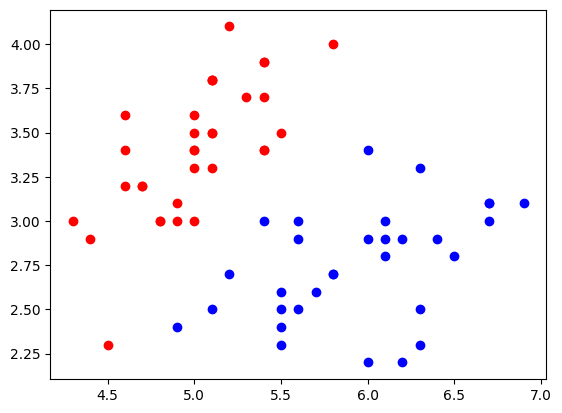

In [41]:
from matplotlib import pyplot as plt
data1 = data_train[np.argmax(lab_train_onehot,axis=1) == 0]
data2 = data_train[np.argmax(lab_train_onehot,axis=1) == 1]

plt.scatter(data1[:,0],data1[:,1],color='r')
plt.scatter(data2[:,0],data2[:,1],color='b')


In [45]:
data_train[np.argmax(lab_train_onehot,axis=1) == 0]

array([[5.7, 3.8, 1.7, 0.3],
       [4.8, 3. , 1.4, 0.1],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [5.1, 3.8, 1.6, 0.2],
       [5.1, 3.5, 1.4, 0.3],
       [5.4, 3.9, 1.7, 0.4],
       [5.5, 3.5, 1.3, 0.2],
       [5.4, 3.7, 1.5, 0.2],
       [4.6, 3.4, 1.4, 0.3],
       [5.3, 3.7, 1.5, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5. , 3.4, 1.6, 0.4],
       [5.5, 4.2, 1.4, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [5. , 3.2, 1.2, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [5.1, 3.4, 1.5, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [4.5, 2.3, 1.3, 0.3],
       [5.1, 3.5, 1.4, 0.2],
       [5.8, 4. , 1.2, 0.2],
       [5.2, 4.1, 1.5, 0.1],
       [4.6, 3.2, 1.4, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [4.9, 3.1, 1.5, 0.2],
       [4.6, 3.6, 1. , 0.2],
       [4.8, 3.4, 1.9, 0.2],
       [5.1, 3.8, 1.5, 0.3],
       [4.4, 2.9, 1.4, 0.2],
       [4.8, 3. , 1.4, 0.3],
       [4.4, 3.2, 1.3, 0.2]])

In [12]:
layers

[{'w': array([[ 0.07383764,  0.33109148,  0.78631403, -0.46001677],
         [ 0.06662259,  0.26343124,  0.70575556, -0.32741985],
         [-0.15465626, -0.61063048, -1.16054355,  1.07648468],
         [-0.13755163, -0.52198073, -1.19418885,  1.06599005]]),
  'b': array([[ 0.16064566,  0.33397819,  0.70431412, -0.11484732]]),
  'act_fun': <function __main__.relu(z)>,
  'de_act_fun': <function __main__.de_relu(z, h)>},
 {'w': array([[-0.00332852, -0.15423328,  0.03801738,  0.07404529],
         [-0.04637168, -0.56590362,  0.11741541,  0.24964335],
         [-0.01224168, -0.97097512,  0.05547538,  0.12254372],
         [ 0.11212521,  0.48097799, -0.33540822, -0.60859362]]),
  'b': array([[ 0.12313418, -0.32162124,  0.21151595,  0.34435233]]),
  'act_fun': <function __main__.relu(z)>,
  'de_act_fun': <function __main__.de_relu(z, h)>},
 {'w': array([[-0.14415161,  0.08171994,  0.13524393],
         [ 0.01824664, -0.61325195,  0.58333182],
         [ 0.30180271, -0.23556649, -0.03002859],

In [ ]:
layers[0]

In [7]:
o1,o2,o3 = fead_forward(layers=layers,datas=data_train)

In [24]:
o2[0][o2[0]<=0]

array([], dtype=float64)

In [32]:

np.allclose(o2[3],o1[4])

True

In [35]:
o1[4].shape

(100, 128)

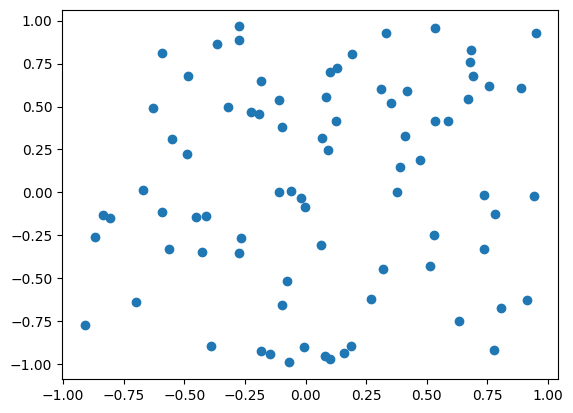

In [26]:
t1 = 2*np.random.random(80) - 1
t2 = 2*np.random.random(80) - 1

x = np.hstack((t1.reshape(-1,1),t2.reshape(-1,1)))
y = np.zeros((80,1))

plt.scatter(x[:,0],x[:,1])



In [8]:


plt.scatter(x1[:,0],x1[:,1])



NameError: name 'plt' is not defined

In [ ]:
load_dataset_iris_my('./data/iris.data',100)

(array([ 0.,  5., 13., 16., 28., 23.,  9.,  6.,  0.]),
 array([-3.        , -2.33333333, -1.66666667, -1.        , -0.33333333,
         0.33333333,  1.        ,  1.66666667,  2.33333333,  3.        ]),
 <BarContainer object of 9 artists>)

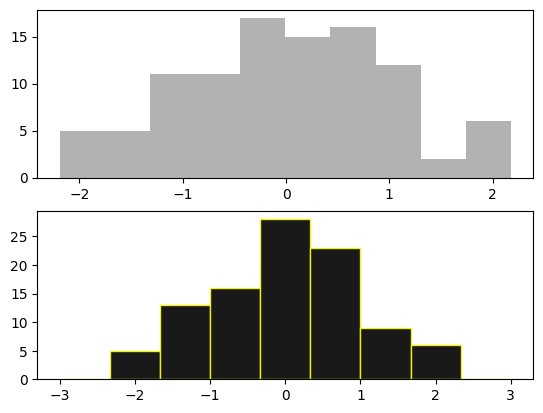

In [4]:
data = np.random.randn(100)
    
fig = plt.figure(5)
# 整数bin
ax1 = fig.add_subplot(2,1,1)
ax1.hist(data, bins=10, color='k', alpha=0.3)

# 区间bin
ax2 = fig.add_subplot(2,1,2)
m_bin = np.linspace(-3,3,10)
ax2.hist(data, bins=m_bin,ec="yellow", fc="k",alpha=0.9)

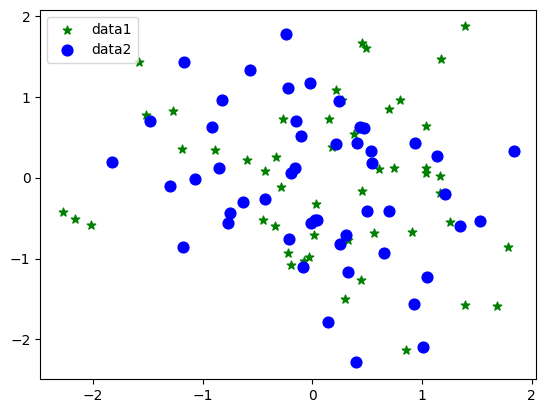

In [8]:
# fig = plt.figure(6)
ax2 = plt.subplot(111)
data = np.random.randn(2,50)
ax2.scatter(data[0,:],data[1,:],s=40,c='g',marker='*',label = 'data1')
data = np.random.randn(2,50)
ax2.scatter(data[0,:],data[1,:],s=60,c='b',marker='o',label = 'data2')
ax2.legend(loc='best')

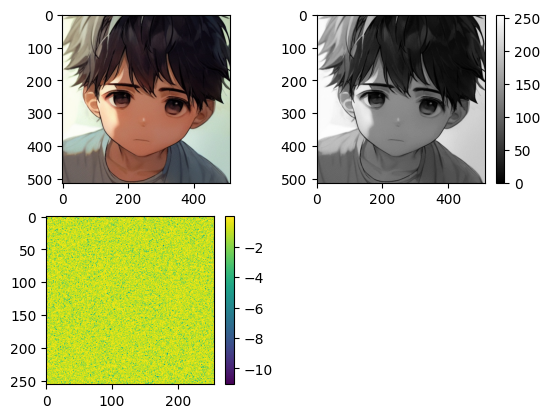

In [9]:
fig = plt.figure('IMG')
ax1 = fig.add_subplot(2,2,1)
ax2 = fig.add_subplot(2,2,2)
ax3 = fig.add_subplot(2,2,3)

img = cv2.imread("./mydata/0.jpg")
img1 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 显示彩色图
ax1.imshow(img1)

# 显示灰度图
im_g = ax2.imshow(gray,cmap='gray',vmin=0,vmax =255)
plt.colorbar(im_g,ax =ax2 )

# 将一个随机矩阵 进行颜色显示
data = np.log(np.random.rand(256,256))
img_r = ax3.imshow(data)
plt.colorbar(img_r,ax = ax3)